In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, classification_report, f1_score
from xgboost import XGBClassifier

# 1. Load & engineer physics features
df = pd.read_csv("../data/ai4i2020.csv")
df["Angular_velocity_rad_s"] = df["Rotational speed [rpm]"] * (2 * np.pi / 60)
df["Power_W"] = df["Torque [Nm]"] * df["Angular_velocity_rad_s"]
df["Temp_diff_K"] = df["Process temperature [K]"] - df["Air temperature [K]"]
df["Overstrain_proxy"] = df["Torque [Nm]"] * df["Tool wear [min]"]
df["Type_encoded"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

drop_cols = ["UDI", "Product ID", "Type", "Machine failure", "TWF", "HDF", "PWF", "OSF", "RNF"]
X = df.drop(columns=drop_cols)
y = df["Machine failure"]
X.columns = [col.replace("[", "").replace("]", "").replace(" ", "_") for col in X.columns]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. Train XGBoost
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train)
print("Model trained successfully.")

Model trained successfully.


In [2]:
# Get predicted failure probabilities (0.0 to 1.0)
y_probs = xgb_model.predict_proba(X_test)[:, 1]

# Compute precision, recall, and F1 for every threshold
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-8)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Default Threshold (0.50) F1-Score: {f1_score(y_test, (y_probs >= 0.50).astype(int)):.4f}")
print(f"Optimal Threshold ({best_threshold:.2f}) F1-Score: {f1_scores[best_idx]:.4f}\n")

print("=== REPORT WITH TUNED THRESHOLD ===")
tuned_preds = (y_probs >= best_threshold).astype(int)
print(classification_report(y_test, tuned_preds, target_names=["Healthy", "Failure"]))



Default Threshold (0.50) F1-Score: 0.8116
Optimal Threshold (0.91) F1-Score: 0.8730

=== REPORT WITH TUNED THRESHOLD ===
              precision    recall  f1-score   support

     Healthy       0.99      1.00      1.00      1932
     Failure       0.95      0.81      0.87        68

    accuracy                           0.99      2000
   macro avg       0.97      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000



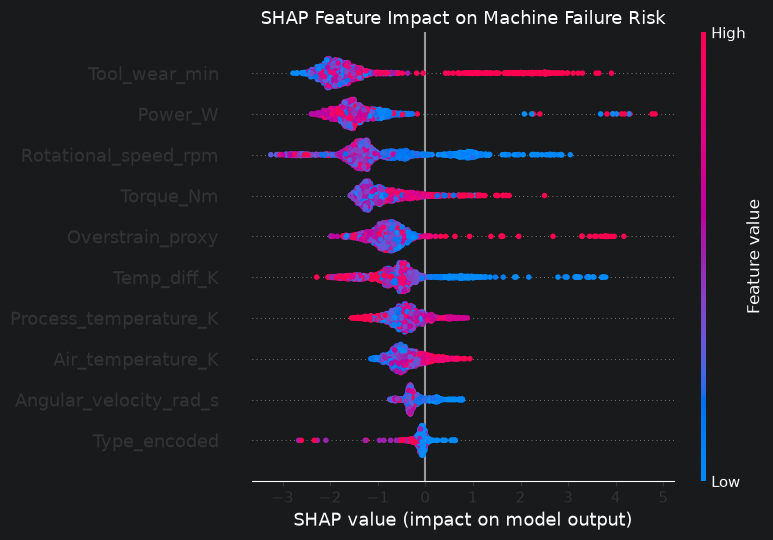

In [3]:
os.makedirs("../results", exist_ok=True)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)


plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Feature Impact on Machine Failure Risk", fontsize=13)
plt.tight_layout()
plt.savefig("../results/shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

In [4]:
os.makedirs("../models", exist_ok=True)

artifact = {
    "model": xgb_model,
    "threshold": float(best_threshold),
    "feature_names": list(X.columns),
}
joblib.dump(artifact, "../models/xgb_predictive_maintenance.joblib")
print("Saved model artifact to ../models/xgb_predictive_maintenance.joblib")

Saved model artifact to ../models/xgb_predictive_maintenance.joblib
